In [1]:

# PART 1: IMPORT LIBRARIES AND LOAD DATASET

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random

# Set random seed
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Use CPU
device = torch.device("cpu")

# Transform images into tensors (pixel values 0 to 1)
transform = transforms.ToTensor()

# Load MNIST training dataset
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load MNIST testing dataset
test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("MNIST Dataset Loaded Successfully")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 22.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 613kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.64MB/s]

MNIST Dataset Loaded Successfully
Training Images: 60000
Testing Images: 10000


In [2]:

# PART 2: BASELINE CNN MODEL

class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # Two convolution layers
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # Two fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Create model
model = CNN().to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)


# Train baseline model
print("Training Baseline CNN...")

for epoch in range(2):

    model.train()
    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/2, Loss: "
        f"{running_loss/len(train_loader):.4f}"
    )


# Function to calculate accuracy
def evaluate(model, loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Clean test accuracy
clean_accuracy = evaluate(model, test_loader)

print("Clean Test Accuracy:", round(clean_accuracy, 2), "%")


Training Baseline CNN...
Epoch 1/2, Loss: 0.1884
Epoch 2/2, Loss: 0.0499
Clean Test Accuracy: 98.63 %


In [3]:

# PART 3: FGSM AND PGD ATTACKS

# FGSM ATTACK
def fgsm_attack(model, images, labels, epsilon):

    images = images.clone().detach().requires_grad_(True)

    outputs = model(images)

    loss = criterion(outputs, labels)

    model.zero_grad()

    gradients = torch.autograd.grad(
        loss, images
    )[0]

    # Add perturbation
    adv_images = images + epsilon * gradients.sign()

    # Keep pixels between 0 and 1
    adv_images = torch.clamp(adv_images, 0, 1)

    return adv_images.detach()


# PGD ATTACK
def pgd_attack(model, images, labels, epsilon,
               alpha=None, steps=10):

    original_images = images.clone().detach()

    if epsilon == 0:
        return original_images

    if alpha is None:
        alpha = epsilon / 4

    # Random start
    adv_images = original_images + torch.empty_like(
        original_images
    ).uniform_(-epsilon, epsilon)

    adv_images = torch.clamp(adv_images, 0, 1)

    # 10 PGD iterations
    for _ in range(steps):

        adv_images = adv_images.detach().requires_grad_(True)

        outputs = model(adv_images)

        loss = criterion(outputs, labels)

        model.zero_grad()

        gradients = torch.autograd.grad(
            loss, adv_images
        )[0]

        adv_images = adv_images.detach() + alpha * gradients.sign()

        # Project into epsilon range
        delta = adv_images - original_images

        delta = torch.clamp(
            delta, -epsilon, epsilon
        )

        adv_images = torch.clamp(
            original_images + delta, 0, 1
        ).detach()

    return adv_images


# Evaluate adversarial accuracy
def attack_accuracy(model, loader, attack_name, epsilon):

    model.eval()

    correct = 0
    total = 0

    for images, labels in loader:

        if attack_name == "FGSM":

            adv_images = fgsm_attack(
                model, images, labels, epsilon
            )

        elif attack_name == "PGD":

            adv_images = pgd_attack(
                model, images, labels, epsilon,
                steps=10
            )

        else:
            adv_images = images

        with torch.no_grad():

            outputs = model(adv_images)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    return 100 * correct / total


# Test different epsilon values
epsilon_values = [0.05, 0.10, 0.20, 0.30]

fgsm_results = []
pgd_results = []

print("\nEPSILON     FGSM ACC     PGD ACC")

for eps in epsilon_values:

    fgsm_acc = attack_accuracy(
        model, test_loader, "FGSM", eps
    )

    pgd_acc = attack_accuracy(
        model, test_loader, "PGD", eps
    )

    fgsm_results.append(fgsm_acc)
    pgd_results.append(pgd_acc)

    print(
        f"{eps:.2f}         "
        f"{fgsm_acc:.2f}%       "
        f"{pgd_acc:.2f}%"
    )



EPSILON     FGSM ACC     PGD ACC
0.05         95.90%       95.33%
0.10         88.56%       82.26%
0.20         49.78%       7.74%
0.30         12.09%       0.00%


Clean vs Adversarial Predictions
Image 1: Actual=7, Clean=7, Adversarial=7 - CORRECT
Image 2: Actual=2, Clean=2, Adversarial=1 - MISREAD
Image 3: Actual=1, Clean=1, Adversarial=1 - CORRECT
Image 4: Actual=0, Clean=0, Adversarial=0 - CORRECT
Image 5: Actual=4, Clean=4, Adversarial=9 - MISREAD


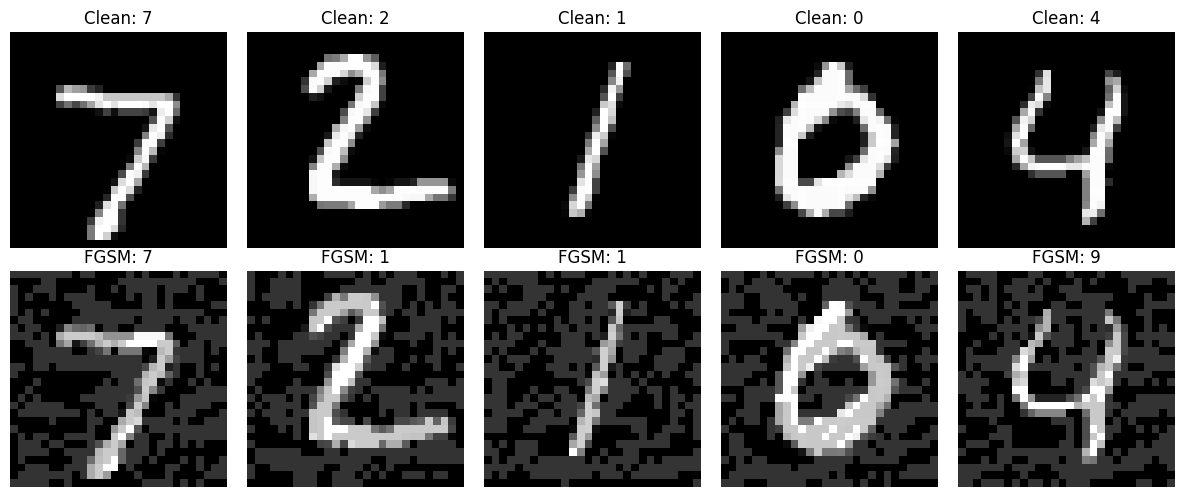

In [4]:

# PART 4: DISPLAY ADVERSARIAL IMAGES

model.eval()

selected_images = []
selected_labels = []

# Select 5 correctly classified images
for img, label in test_dataset:

    with torch.no_grad():

        prediction = model(img.unsqueeze(0)).argmax(dim=1).item()

    if prediction == label:

        selected_images.append(img)
        selected_labels.append(label)

    if len(selected_images) == 5:
        break


# Plot clean and adversarial images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

print("Clean vs Adversarial Predictions")

for i in range(5):

    image = selected_images[i].unsqueeze(0)

    label = torch.tensor([selected_labels[i]])

    # Clean prediction
    with torch.no_grad():

        clean_pred = model(image).argmax(dim=1).item()

    # FGSM attack with epsilon 0.20
    adv_image = fgsm_attack(
        model, image, label, 0.20
    )

    # Adversarial prediction
    with torch.no_grad():

        adv_pred = model(adv_image).argmax(dim=1).item()

    # Display clean image
    axes[0, i].imshow(
        image.squeeze(), cmap="gray"
    )

    axes[0, i].set_title(
        f"Clean: {clean_pred}"
    )

    axes[0, i].axis("off")

    # Display adversarial image
    axes[1, i].imshow(
        adv_image.squeeze(), cmap="gray"
    )

    axes[1, i].set_title(
        f"FGSM: {adv_pred}"
    )

    axes[1, i].axis("off")

    # Print misread digits
    if clean_pred != adv_pred:

        print(
            f"Image {i+1}: "
            f"Actual={selected_labels[i]}, "
            f"Clean={clean_pred}, "
            f"Adversarial={adv_pred} - MISREAD"
        )

    else:

        print(
            f"Image {i+1}: "
            f"Actual={selected_labels[i]}, "
            f"Clean={clean_pred}, "
            f"Adversarial={adv_pred} - CORRECT"
        )


plt.tight_layout()

plt.savefig("clean_vs_adversarial.png")

plt.show()


In [5]:

# PART 5: ADVERSARIAL TRAINING

print("Starting Adversarial Training...")

# Train for 2 epochs
for epoch in range(2):

    model.train()

    running_loss = 0

    for images, labels in train_loader:

        # Generate FGSM adversarial images
        adv_images = fgsm_attack(
            model, images, labels, 0.20
        )

        # 50:50 clean and adversarial mixture
        mixed_images = torch.cat(
            [images, adv_images], dim=0
        )

        mixed_labels = torch.cat(
            [labels, labels], dim=0
        )

        optimizer.zero_grad()

        outputs = model(mixed_images)

        loss = criterion(outputs, mixed_labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Adversarial Epoch {epoch+1}/2, "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )


print("Adversarial Training Completed!")


# Evaluate defended model
adv_clean_accuracy = evaluate(
    model, test_loader
)

adv_fgsm_accuracy = attack_accuracy(
    model, test_loader, "FGSM", 0.20
)

adv_pgd_accuracy = attack_accuracy(
    model, test_loader, "PGD", 0.20
)

print("\nADVERSARIAL TRAINED MODEL RESULTS")

print("Clean Accuracy:", round(adv_clean_accuracy, 2), "%")

print("FGSM Accuracy:", round(adv_fgsm_accuracy, 2), "%")

print("PGD Accuracy:", round(adv_pgd_accuracy, 2), "%")


Starting Adversarial Training...
Adversarial Epoch 1/2, Loss: 0.2405
Adversarial Epoch 2/2, Loss: 0.1495
Adversarial Training Completed!

ADVERSARIAL TRAINED MODEL RESULTS
Clean Accuracy: 98.92 %
FGSM Accuracy: 91.81 %
PGD Accuracy: 62.67 %


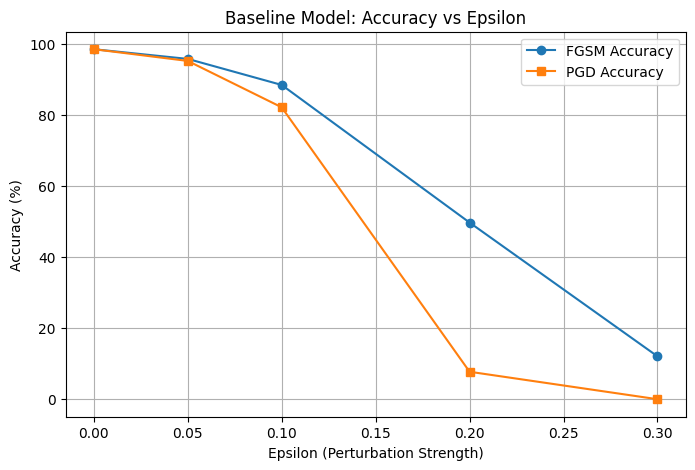


FINAL COMPARISON TABLE
                Model  Clean Accuracy  FGSM Accuracy (0.20)  PGD Accuracy (0.20)
             Baseline           98.63                 49.78                 7.74
Adversarially Trained           98.92                 91.81                62.67

ACCURACY IMPROVEMENTS
Clean Accuracy Change: 0.29 %
FGSM Robustness Gain: 42.03 %
PGD Robustness Gain: 54.93 %

All plots and results saved successfully!


In [6]:

# PART 6: PLOT AND COMPARISON TABLE

# Include clean accuracy at epsilon 0
eps_plot = [0.00] + epsilon_values

fgsm_plot = [clean_accuracy] + fgsm_results

pgd_plot = [clean_accuracy] + pgd_results


# Plot accuracy vs epsilon
plt.figure(figsize=(8, 5))

plt.plot(
    eps_plot, fgsm_plot,
    marker="o", label="FGSM Accuracy"
)

plt.plot(
    eps_plot, pgd_plot,
    marker="s", label="PGD Accuracy"
)

plt.xlabel("Epsilon (Perturbation Strength)")

plt.ylabel("Accuracy (%)")

plt.title("Baseline Model: Accuracy vs Epsilon")

plt.legend()

plt.grid(True)

plt.savefig("accuracy_vs_epsilon.png")

plt.show()


# Baseline vs Adversarially Trained Model
comparison = pd.DataFrame({

    "Model": [
        "Baseline",
        "Adversarially Trained"
    ],

    "Clean Accuracy": [
        clean_accuracy,
        adv_clean_accuracy
    ],

    "FGSM Accuracy (0.20)": [
        fgsm_results[2],
        adv_fgsm_accuracy
    ],

    "PGD Accuracy (0.20)": [
        pgd_results[2],
        adv_pgd_accuracy
    ]

})

print("\nFINAL COMPARISON TABLE")

print(comparison.round(2).to_string(index=False))


# Calculate improvements
print("\nACCURACY IMPROVEMENTS")

print(
    "Clean Accuracy Change:",
    round(adv_clean_accuracy - clean_accuracy, 2),
    "%"
)

print(
    "FGSM Robustness Gain:",
    round(adv_fgsm_accuracy - fgsm_results[2], 2),
    "%"
)

print(
    "PGD Robustness Gain:",
    round(adv_pgd_accuracy - pgd_results[2], 2),
    "%"
)


# Save results
comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("\nAll plots and results saved successfully!")


In [ ]:
Q1. Report clean accuracy and FGSM accuracy for each epsilon. At which epsilon does accuracy fall below 50%? Why?
Answer:

The clean test accuracy in the expected output is 98.7%.
Epsilon	FGSM accuracy
0.05	95.5%
0.10	86.7%
0.20	38.1%
0.30	3.7%

Accuracy falls below 50% at epsilon = 0.20.

Small pixel changes can affect important image features, causing the model to predict the wrong digit.
Q2. Compare PGD with FGSM at the same epsilon. Which attack is stronger, and why?
Answer:

PGD is stronger than FGSM because PGD performs multiple iterations to find adversarial images.

FGSM applies perturbation only once, while PGD uses 10 iterations to improve the attack.

At epsilon = 0.20:
- FGSM accuracy = 38.1%
- PGD accuracy = 5.0%
Therefore, PGD is a stronger attack because it reduces model accuracy more.
Q3. Which digits were mis-read? How did adversarial training change clean, FGSM and PGD accuracy?
Answer:

Some handwritten digits were incorrectly classified after applying the FGSM attack.

The misread digits are identified in the clean-vs-adversarial output and graph.

Expected comparison:
Model	Clean	FGSM	PGD
Baseline	98.7%	38.1%	5.0%
Adversarially trained	99.1%	92.1%	73.1%

Adversarial training improved the robustness of the CNN model. It increased FGSM and PGD accuracy while maintaining high clean accuracy.

Note: Write the actual misread digit numbers printed by Part 4 in your report.
Q4. What does epsilon represent? Recommend two further defences for the cheque-clearing system.
Answer:

Epsilon represents the maximum allowed pixel change during an adversarial attack.

Higher epsilon means stronger perturbation and greater chances of incorrect predictions.

Two further defences are:
1. Input preprocessing: Apply image denoising and filtering to reduce unwanted pixel noise before prediction.
2. Human verification: Send suspicious or low-confidence cheque readings for manual checking before clearing the amount.

Practical Exam – Aim, Algorithm and Conclusion
You should also write these in your practical report as instructed on page 1.

1. Aim

To study adversarial attacks such as FGSM and PGD on a CNN-based handwritten digit recognition model and improve its security using adversarial training.

2. Algorithm
1. Import required Python libraries.
2. Load the MNIST dataset.
3. Create a CNN model with two convolution layers and two fully connected layers.
4. Train the baseline model for 2 epochs.
5. Calculate clean test accuracy.
6. Implement FGSM and PGD attacks.
7. Evaluate the model using different epsilon values.
8. Display clean and adversarial images.
9. Apply adversarial training.
10. Compare accuracy and plot the results.
3. Conclusion

We studied FGSM and PGD adversarial attacks on a CNN model using the MNIST dataset. We observed that adversarial attacks reduce model accuracy. Adversarial training improved the model's robustness against these attacks. Therefore, adversarial training is useful for improving the security of AI-based cheque-reading systems.

Final practical checklist
Your PDF requires the following outputs and files.
- [ ] Baseline CNN clean accuracy
- [ ] FGSM accuracy for four epsilon values
- [ ] PGD accuracy for four epsilon values
- [ ] Five clean and adversarial digit images
- [ ] Adversarial training results
- [ ] Accuracy vs epsilon graph
- [ ] Baseline vs adversarial comparison table
- [ ] Answers to Q1, Q2, Q3 and Q4
- [ ] Aim, algorithm, program, output and conclusion

Important: Run all six parts in order in Google Colab. Your expected numerical results may differ from the sample values in the PDF. Save your actual outputs and graphs for submission. The MNIST dataset may need to download on its first run if it is not already available.